# Task 5: Polynomial OLS and Ridge Regression

## Assigned model

The selected branch is $\xi_{15}=2$.

The displayed model is a degree-10 polynomial:

$$
f_\alpha(x)
=
\alpha_0+\alpha_1x+\cdots+\alpha_{10}x^{10}.
$$

This formula contains 11 coefficients, including the intercept. The calculation follows the displayed formula rather than the inconsistent wording describing ten parameters.

There are 22 supplied observations $(x_i,y_i)$.

## Objectives

1. Calculate the ordinary least-squares coefficient estimates
2. Calculate ridge-regularized coefficient estimates
3. Define and justify the penalty convention and its weight
4. Compare fit error, coefficient shrinkage, and validation performance
5. Explain the numerical methods and limitations

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

data = np.array([
    (15, 1626639709458.76),
    (-6, 215903959.68),
    (17, 5634674657106.69),
    (-14, 948255878968.41),
    (2, 2453.01),
    (12, 176891864016.73),
    (-5, 38455500.59),
    (8, 2741446963.17),
    (-3, 277968.96),
    (-16, 3390875179551.8),
    (4, 2649990.77),
    (-9, 11403619911.64),
    (-11, 89910534374.96),
    (-19, 19608390963199.21),
    (-12, 200804985369.02),
    (-13, 453441370414.22),
    (18, 9897917086496.97),
    (-8, 3816397713.47),
    (-7, 977873055.85),
    (-10, 33506954184.6),
    (20, 29726123569978.77),
    (7, 752826486.45),
], dtype=float)

x = data[:, 0]
y = data[:, 1]

degree = 10
n_parameters = degree + 1
n_observations = len(x)

figure_directory = Path("figures")
figure_directory.mkdir(parents=True, exist_ok=True)

assert n_observations == 22
assert len(np.unique(x)) == n_observations
assert np.all(np.isfinite(data))

print(f"Observations: {n_observations}")
print(f"Polynomial degree: {degree}")
print(f"Coefficients including intercept: {n_parameters}")
print(f"Input range: {x.min():.0f} to {x.max():.0f}")

Observations: 22
Polynomial degree: 10
Coefficients including intercept: 11
Input range: -19 to 20


## Scaling and design matrix

Directly constructing high powers of the original inputs produces columns with very different magnitudes.

Define fixed scaling constants

$$
c=20,\qquad d=10^{13},
$$

and scaled variables

$$
t_i=\frac{x_i}{c},
\qquad
z_i=\frac{y_i}{d}.
$$

The scaled polynomial is

$$
g_\beta(t)=\sum_{j=0}^{10}\beta_jt^j,
$$

so that the predicted response in original units is

$$
\widehat{y}(x)=d\,g_\beta(x/c).
$$

The original polynomial coefficients are recovered by

$$
\alpha_j=\frac{d}{c^j}\beta_j
$$

Define the design matrix A by

$$
A_{ij}=t_i^j,
\qquad i=1,\ldots,22,\quad j=0,\ldots,10.
$$

Because the inputs are distinct, this degree-10 polynomial design has full column rank. A nonzero polynomial of degree at most 10 cannot vanish at all 22 distinct inputs.

Scaling changes the coefficient representation but does not change the set of available polynomial functions. It therefore preserves the OLS fitting problem after conversion back to original units.

For ridge regression, the coefficient representation affects the penalty. The chosen penalty is defined explicitly below.

In [2]:
x_scale = 20.0
y_scale = 1e13

t = x / x_scale
z = y / y_scale

# increases exp value by t when true
A = np.vander(t, N=n_parameters, increasing=True)

# to assess scaling
A_unscaled = np.vander(x, N=n_parameters, increasing=True)

rank = np.linalg.matrix_rank(A)
condition_scaled = np.linalg.cond(A)
condition_unscaled = np.linalg.cond(A_unscaled)

assert rank == n_parameters

print(f"Design matrix shape: {A.shape}")
print(f"Scaled matrix rank: {rank}")
print(f"Unscaled condition number: {condition_unscaled:.3e}")
print(f"Scaled condition number: {condition_scaled:.3e}")

Design matrix shape: (22, 11)
Scaled matrix rank: 11
Unscaled condition number: 1.112e+13
Scaled condition number: 4.913e+03


## Ordinary least squares

The original polynomial model is

$$
f_\alpha(x)=\sum_{j=0}^{10}\alpha_jx^j.
$$

The OLS estimate minimizes

$$
\sum_{i=1}^{22}\left(y_i-f_\alpha(x_i)\right)^2.
$$

With the scaling defined above,

$$
t_i=x_i/c,\qquad z_i=y_i/d,
\qquad
\alpha_j=d\beta_j/c^j,
$$

where $c=20$ and $d=10^{13}$, the equivalent scaled objective is

$$
J_0(\beta)=\|\mathbf z-A\beta\|_2^2.
$$

Differentiating gives the normal equations

$$
A^\mathsf{T}A\widehat{\beta}_{OLS}
=
A^\mathsf{T}\mathbf z.
$$

Since A has full column rank, the solution is unique.

The implementation solves the least-squares problem directly rather than explicitly forming and inverting the normal-equation matrix.

## Ridge penalty on the original coefficients

The chosen ridge objective is

$$
J_\lambda(\alpha)
=
\sum_{i=1}^{22}\left(y_i-f_\alpha(x_i)\right)^2
+
\lambda\sum_{j=1}^{10}\alpha_j^2.
$$

The intercept $\alpha_0$ is not penalized. The penalty gives equal weight to the squared non-intercept coefficients in the original polynomial basis.

The loss is a sum of squared errors, not a mean squared error. Reported penalty values refer to this convention.

Substituting $\alpha_j=d\beta_j/c^j$ and dividing the entire objective
by $d^2$ gives

$$
\widetilde{J}_\lambda(\beta)
=
\|\mathbf z-A\beta\|_2^2
+
\lambda\sum_{j=1}^{10}\frac{\beta_j^2}{c^{2j}}.
$$

Define

$$
D=\operatorname{diag}
\left(0,c^{-1},c^{-2},\ldots,c^{-10}\right).
$$

Then

$$
\widetilde{J}_\lambda(\beta)
=
\|\mathbf z-A\beta\|_2^2
+
\lambda\|D\beta\|_2^2.
$$

Thus, scaling improves the numerical representation while preserving the stated penalty on the original coefficients.

Differentiating yields

$$
(A^\mathsf{T}A+\lambda D^\mathsf{T}D)
\widehat{\beta}_\lambda
=
A^\mathsf{T}\mathbf z.
$$

Equivalently, solve the augmented least-squares problem

$$
\min_\beta
\left\|
\underbrace{
\begin{pmatrix}
A\\
\sqrt{\lambda}D
\end{pmatrix}
}_{B}
\beta
-
\underbrace{
\begin{pmatrix}
\mathbf z\\
\mathbf0
\end{pmatrix}
}_{\mathbf v}
\right\|_2^2.
$$

## Numerical column scaling

For numerical stability, each column of B is divided by its Euclidean norm. Let C be the diagonal matrix containing those positive norms.

Writing

$$
\eta=C\beta
$$

gives the equivalent problem

$$
\min_\eta\|BC^{-1}\eta-\mathbf v\|_2^2.
$$

After solving, recover $\beta=C^{-1}\eta$.

This is an invertible change of variables. It does not change the objective or introduce a different regularization penalty.

In [10]:
# keep equal penalties on non-intercept coefficients
penalty_diagonal = x_scale ** (-np.arange(n_parameters, dtype=float))
penalty_diagonal[0] = 0.0
D = np.diag(penalty_diagonal)


def least_squares_system(A_train, z_train, penalty):
    """Construct the scaled system for the original-coefficient penalty"""
    if penalty < 0:
        raise ValueError("The penalty must be nonnegative")

    if penalty == 0:
        matrix = A_train
        target = z_train
    else:
        matrix = np.vstack([
            A_train,
            np.sqrt(penalty) * D,
        ])

        target = np.concatenate([
            z_train,
            np.zeros(n_parameters),
        ])

    # balance columns
    column_norms = np.linalg.norm(matrix, axis=0)

    if np.any(column_norms == 0):
        raise ValueError("The system contains a zero column")

    equilibrated_matrix = matrix / column_norms

    return equilibrated_matrix, target, column_norms


def fit_polynomial(A_train, z_train, penalty):
    """Fit OLS or ridge penalizing the original alpha coefficients"""
    matrix, target, column_norms = least_squares_system(
        A_train, z_train, penalty
    )

    eta, _, fitted_rank, _ = np.linalg.lstsq(
        matrix,
        target,
        rcond=None,
    )

    if fitted_rank != n_parameters:
        raise ValueError("The fitted system does not have full column rank")

    beta = eta / column_norms
    return beta


def original_coefficients(beta):
    """Convert scaled coefficients to alpha_0, ..., alpha_10"""
    powers = np.arange(n_parameters)
    return y_scale * beta / x_scale**powers


def training_rmse(beta):
    """Root mean squared training error in original response units"""
    residuals = y_scale * (A @ beta - z)
    return float(np.sqrt(np.mean(residuals**2)))


beta_ols = fit_polynomial(A, z, penalty=0.0)
alpha_ols = original_coefficients(beta_ols)

print(f"OLS training RMSE: {training_rmse(beta_ols):.6e}")
print("Original-coordinate OLS coefficients:")

for j, coefficient in enumerate(alpha_ols):
    print(f"alpha_{j:02d} = {coefficient:.9e}")

OLS training RMSE: 1.544269e+10
Original-coordinate OLS coefficients:
alpha_00 = -2.527808940e+10
alpha_01 = 2.536515374e+09
alpha_02 = 3.145184841e+09
alpha_03 = -5.713209323e+07
alpha_04 = -8.334538082e+07
alpha_05 = 3.019133378e+04
alpha_06 = 7.827729742e+05
alpha_07 = 2.455641449e+03
alpha_08 = -2.938461653e+03
alpha_09 = -9.494960625e+00
alpha_10 = 6.736424039e+00


## Selecting and comparing penalty weights

Training error alone cannot justify choosing ridge over OLS because OLS already minimizes the unpenalized training error.

Leave-one-out cross-validation is used to compare candidate penalties.

For each observation i:

1. Fit the polynomial to the other 21 observations
2. Predict the omitted response at $x_i$
3. Record the squared prediction error

The validation score is

$$
CV(\lambda)
=
\frac{1}{22}
\sum_{i=1}^{22}
\left(
y_i-\widehat{f}_{\lambda}^{(-i)}(x_i)
\right)^2.
$$

Its square root is reported in original response units.

Positive penalty candidates are logarithmically spaced from $10^{-8}$ to $10^{24}$, using 65 values. OLS, corresponding to $\lambda=0$, is evaluated separately.

The broad range accommodates the large differences in scale among the original polynomial coefficients and the response values.

These penalties apply to the original non-intercept coefficients, not equally to the scaled coefficients. Their numerical magnitudes are therefore not directly comparable with penalties from the previous scaled-coefficient formulation.

The selected value is the best positive candidate on this grid; it is not claimed to be the exact optimum over all positive values.

In [11]:
def loocv_rmse(penalty):
    """Leave-one-out prediction RMSE in original response units"""
    errors = np.empty(n_observations)

    for i in range(n_observations):
        training_mask = np.arange(n_observations) != i

        beta = fit_polynomial(
            A[training_mask],
            z[training_mask],
            penalty,
        )

        predicted_scaled = A[i] @ beta
        errors[i] = y_scale * (predicted_scaled - z[i])

    return float(np.sqrt(np.mean(errors**2)))


penalty_grid = np.logspace(-8, 24, 65)

ols_cv_rmse = loocv_rmse(0.0)

ridge_cv_scores = np.array([
    loocv_rmse(penalty)
    for penalty in penalty_grid
])

best_index = int(np.argmin(ridge_cv_scores))
selected_penalty = float(penalty_grid[best_index])
selected_cv_rmse = float(ridge_cv_scores[best_index])

beta_ridge = fit_polynomial(A, z, selected_penalty)
alpha_ridge = original_coefficients(beta_ridge)

# larger penalty = coefficient shrinkage
illustrative_penalty = 1e20
beta_stronger = fit_polynomial(A, z, illustrative_penalty)
alpha_stronger = original_coefficients(beta_stronger)

print(f"OLS LOOCV RMSE: {ols_cv_rmse:.6e}")
print(f"Selected positive penalty: {selected_penalty:.6e}")
print(f"Selected ridge LOOCV RMSE: {selected_cv_rmse:.6e}")

if best_index in (0, len(penalty_grid) - 1):
    print("The selected penalty lies at a boundary of the tested grid")
else:
    print("The selected penalty is inside the tested grid")

if selected_cv_rmse < ols_cv_rmse:
    print("The selected ridge candidate has lower LOOCV error than OLS")
else:
    print("The tested ridge penalties do not improve on the OLS baseline")

OLS LOOCV RMSE: 3.148175e+11
Selected positive penalty: 3.162278e+17
Selected ridge LOOCV RMSE: 1.753460e+11
The selected penalty is inside the tested grid
The selected ridge candidate has lower LOOCV error than OLS


In [5]:
models = [
    ("OLS", 0.0, beta_ols),
    ("Selected ridge", selected_penalty, beta_ridge),
    ("Stronger ridge", illustrative_penalty, beta_stronger),
]

print(
    f"{'Model':<18} {'Penalty':>12} "
    f"{'Train RMSE':>15} {'LOOCV RMSE':>15} "
    f"{'||alpha[1:]||':>16}"
)

for name, penalty, beta in models:
    alpha_coefficients = original_coefficients(beta)

    print(
        f"{name:<18} "
        f"{penalty:12.3e} "
        f"{training_rmse(beta):15.6e} "
        f"{loocv_rmse(penalty):15.6e} "
        f"{np.linalg.norm(alpha_coefficients[1:]):16.6e}"
    )

    # verify scaled penalty reps og penalty
    assert np.isclose(
        np.linalg.norm(D @ beta),
        np.linalg.norm(alpha_coefficients[1:]) / y_scale,
        rtol=1e-10,
        atol=0.0,
    )

    # first-order optimality in the balanced coordinates
    matrix, target, column_norms = least_squares_system(
        A, z, penalty
    )

    eta = column_norms * beta

    optimality_residual = matrix.T @ (matrix @ eta - target)
    relative_residual = (
        np.linalg.norm(optimality_residual)
        / (1 + np.linalg.norm(matrix.T @ target))
    )

    assert relative_residual < 1e-10

#b penalty-equivalence first-order optimality checks passed

Model                   Penalty      Train RMSE      LOOCV RMSE    ||beta[1:]||
OLS                   0.000e+00    1.544269e+10    3.148175e+11       11.462993
Selected ridge        1.000e-12    1.544269e+10    3.148175e+11       11.462985
Stronger ridge        1.000e-04    4.065655e+10    7.547837e+11        3.236050


In [12]:
print(
    f"{'Coefficient':<13} "
    f"{'OLS':>19} "
    f"{'Selected ridge':>19} "
    f"{'Stronger ridge':>19}"
)

for j in range(n_parameters):
    print(
        f"{'alpha_' + str(j):<13} "
        f"{alpha_ols[j]:19.9e} "
        f"{alpha_ridge[j]:19.9e} "
        f"{alpha_stronger[j]:19.9e}"
    )

Coefficient                   OLS      Selected ridge      Stronger ridge
alpha_0          -2.527808940e+10     1.673955045e+10    -2.194829269e+10
alpha_1           2.536515374e+09     1.929485268e-07    -4.284039579e-08
alpha_2           3.145184841e+09     5.724819346e-05    -7.007519177e-07
alpha_3          -5.713209323e+07    -1.550500108e-04    -9.817411033e-06
alpha_4          -8.334538082e+07     8.227175599e-03    -2.207336495e-04
alpha_5           3.019133378e+04    -5.944864952e-02    -2.242168063e-03
alpha_6           7.827729742e+05     4.279213859e-01    -5.418836919e-02
alpha_7           2.455641449e+03    -1.392613597e+01    -4.022259154e-01
alpha_8          -2.938461653e+03    -1.192622319e+02    -9.677916803e+00
alpha_9          -9.494960625e+00    -3.177954940e+00    -3.031168699e+00
alpha_10          6.736424039e+00     3.356715212e+00     3.067440044e+00


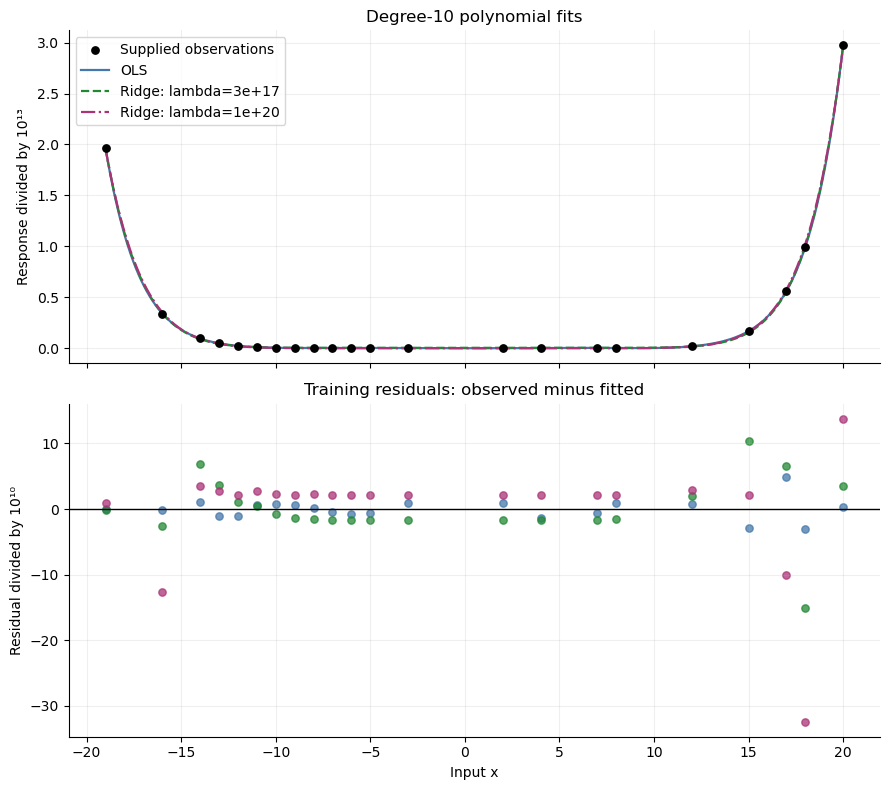

Saved: C:\Users\Usuario\Documents\DocsMain\Informatik\ComputerScienceMSc\advStatistics\workbook\figures\task05_polynomial_fits.pdf


In [13]:
x_grid = np.linspace(x.min(), x.max(), 800)
A_grid = np.vander(
    x_grid / x_scale,
    N=n_parameters,
    increasing=True,
)

styles = [
    ("OLS", beta_ols, "#4477AA", "-"),
    (
        f"Ridge: lambda={selected_penalty:.0e}",
        beta_ridge,
        "#228833",
        "--",
    ),
    (
        f"Ridge: lambda={illustrative_penalty:.0e}",
        beta_stronger,
        "#AA3377",
        "-.",
    ),
]

with plt.rc_context({
    "font.size": 10,
    "pdf.fonttype": 42,
}):
    fig, axes = plt.subplots(
        2, 1,
        figsize=(9, 8),
        sharex=True,
    )

    axes[0].scatter(
        x,
        y / y_scale,
        color="black",
        s=28,
        label="Supplied observations",
        zorder=5,
    )

    for label, beta, color, line_style in styles:
        axes[0].plot(
            x_grid,
            A_grid @ beta,
            color=color,
            linestyle=line_style,
            linewidth=1.6,
            label=label,
        )

        # obs - fitted
        residuals = y - y_scale * (A @ beta)

        axes[1].scatter(
            x,
            residuals / 1e10,
            color=color,
            s=28,
            label=label,
            alpha=0.75,
        )

    axes[0].set_title("Degree-10 polynomial fits")
    axes[0].set_ylabel("Response divided by 10¹³")
    axes[0].legend()

    axes[1].axhline(0, color="black", linewidth=1)
    axes[1].set_xlabel("Input x")
    axes[1].set_ylabel("Residual divided by 10¹⁰")
    axes[1].set_title("Training residuals: observed minus fitted")

    for ax in axes:
        ax.grid(alpha=0.2)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    fig.tight_layout()

    fit_pdf = figure_directory / "task05_polynomial_fits.pdf"
    fit_png = figure_directory / "task05_polynomial_fits.png"

    fig.savefig(fit_pdf, bbox_inches="tight")
    fig.savefig(fit_png, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

print(f"Saved: {fit_pdf.resolve()}")

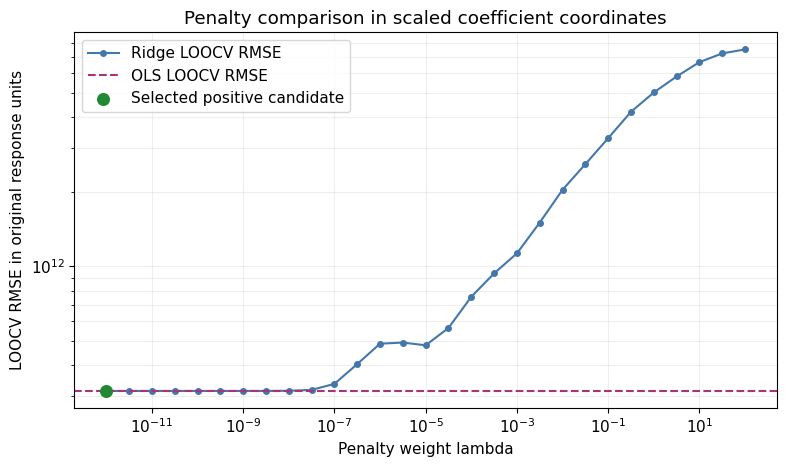

Saved: C:\Users\Usuario\Documents\DocsMain\Informatik\ComputerScienceMSc\advStatistics\workbook\figures\task05_penalty_comparison.pdf


In [8]:
with plt.rc_context({
    "font.size": 11,
    "pdf.fonttype": 42,
}):
    fig, ax = plt.subplots(figsize=(8, 4.8))

    ax.loglog(
        penalty_grid,
        ridge_cv_scores,
        marker="o",
        markersize=4,
        color="#4477AA",
        label="Ridge LOOCV RMSE",
    )

    ax.axhline(
        ols_cv_rmse,
        color="#AA3377",
        linestyle="--",
        label="OLS LOOCV RMSE",
    )

    ax.scatter(
        [selected_penalty],
        [selected_cv_rmse],
        color="#228833",
        s=70,
        zorder=5,
        label="Selected positive candidate",
    )

    ax.set_xlabel("Penalty weight lambda")
    ax.set_ylabel("LOOCV RMSE in original response units")
    ax.set_title("Ridge penalty on original polynomial coefficients")
    ax.grid(which="both", alpha=0.2)
    ax.legend()

    fig.tight_layout()

    cv_pdf = figure_directory / "task05_penalty_comparison.pdf"
    cv_png = figure_directory / "task05_penalty_comparison.png"

    fig.savefig(cv_pdf, bbox_inches="tight")
    fig.savefig(cv_png, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

print(f"Saved: {cv_pdf.resolve()}")

## Results and interpretation

The degree-10 design matrix has full column rank, so the OLS estimate is unique.

Input scaling reduces the design-matrix condition number from approximately $1.11\times10^{13}$ to $4.91\times10^3$. The augmented fitting systems are additionally column-scaled before numerical solution. These invertible changes of variables preserve the stated objectives.

The ridge penalty applies equally to the original non-intercept coefficients:

$$
\lambda\sum_{j=1}^{10}\alpha_j^2.
$$

Among the tested positive penalties, leave-one-out cross-validation selects

$$
\lambda\approx3.162278\times10^{17}.
$$

This value is inside the tested grid. It is the best evaluated candidate, not a proven global optimum over all positive penalties.

The OLS training RMSE is approximately $1.544269\times10^{10}$, and its leave-one-out RMSE is approximately $3.148175\times10^{11}$.

The selected ridge fit has a higher training RMSE of approximately $4.725186\times10^{10}$, but a lower leave-one-out RMSE of approximately $1.753460\times10^{11}$.

Thus, the selected ridge model sacrifices training fit while improving prediction of omitted observations in this comparison.

The norm of the original non-intercept coefficient vector decreases from approximately $4.041820\times10^9$ for OLS to approximately 120.162 for the selected ridge fit.

A stronger illustrative penalty, $\lambda=10^{20}$, reduces that norm further to approximately 10.603. However, its leave-one-out RMSE increases to approximately $2.356628\times10^{11}$.

Therefore, additional coefficient shrinkage does not necessarily
produce better validation performance.

Among the evaluated alternatives, the selected ridge model is preferred
according to the stated leave-one-out criterion. OLS remains the solution
with the smallest unpenalized training error.

## Limitations

The validation calculation uses only 22 supplied points. Omitting
an endpoint requires prediction beyond the remaining training range,
which can be difficult for a high-degree polynomial.

The squared-error objective measures absolute response error.
Because the responses span many orders of magnitude, it does not
give equal importance to relative errors at small and large responses.

The penalty depends on the original monomial basis and the units used.
Its numerical magnitude cannot be compared directly with a penalty
defined on differently scaled coefficients.

The validation scores were used to select the penalty. The selected
score is therefore not an independent test-set assessment.

No claim is made that the fitted polynomial accurately recovers the
unknown function everywhere between the observations or outside the
observed interval.